<a href="https://colab.research.google.com/github/manojss14/ML2_MANOJSS_4NI22CI034/blob/main/ML2_exp09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pgmpy -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

print("Libraries imported successfully!")

Libraries imported successfully!


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [2]:
data = {
    'Weather': [
        'Sunny', 'Sunny', 'Rainy', 'Cloudy',
        'Sunny', 'Rainy', 'Cloudy', 'Sunny',
        'Rainy', 'Cloudy', 'Sunny', 'Rainy',
        'Cloudy', 'Sunny', 'Rainy', 'Cloudy',
        'Sunny', 'Rainy', 'Cloudy', 'Sunny'
    ],

    'Temperature': [
        'Hot', 'Hot', 'Cold', 'Mild',
        'Mild', 'Cold', 'Hot', 'Mild',
        'Cold', 'Mild', 'Hot', 'Mild',
        'Cold', 'Hot', 'Cold', 'Mild',
        'Mild', 'Cold', 'Hot', 'Hot'
    ],

    'Humidity': [
        'High', 'Normal', 'High', 'Normal',
        'High', 'Normal', 'High', 'Normal',
        'High', 'Normal', 'High', 'High',
        'Normal', 'Normal', 'High', 'Normal',
        'High', 'Normal', 'High', 'Normal'
    ],

    'Play_Sports': [
        'No', 'Yes', 'No', 'Yes',
        'No', 'Yes', 'No', 'Yes',
        'No', 'Yes', 'No', 'No',
        'Yes', 'Yes', 'No', 'Yes',
        'No', 'Yes', 'No', 'Yes'
    ]
}

df = pd.DataFrame(data)

# Save dataset
df.to_csv('weather_data.csv', index=False)

print("Dataset created successfully!")

display(df)

Dataset created successfully!


,Weather,Temperature,Humidity,Play_Sports
0,Sunny,Hot,High,No
1,Sunny,Hot,Normal,Yes
2,Rainy,Cold,High,No
3,Cloudy,Mild,Normal,Yes
4,Sunny,Mild,High,No
5,Rainy,Cold,Normal,Yes
6,Cloudy,Hot,High,No
7,Sunny,Mild,Normal,Yes
8,Rainy,Cold,High,No
9,Cloudy,Mild,Normal,Yes


In [3]:
df = pd.read_csv('weather_data.csv')

print("Dataset loaded successfully!")

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nDataset shape:")
print(df.shape)

Dataset loaded successfully!

First five records:


,Weather,Temperature,Humidity,Play_Sports
0,Sunny,Hot,High,No
1,Sunny,Hot,Normal,Yes
2,Rainy,Cold,High,No
3,Cloudy,Mild,Normal,Yes
4,Sunny,Mild,High,No



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Weather      20 non-null     object
 1   Temperature  20 non-null     object
 2   Humidity     20 non-null     object
 3   Play_Sports  20 non-null     object
dtypes: object(4)
memory usage: 772.0+ bytes

Dataset shape:
(20, 4)


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

print("\nCleaned Dataset:")
display(df)

print("Updated Dataset Shape:", df.shape)

Missing Values:
Weather        0
Temperature    0
Humidity       0
Play_Sports    0
dtype: int64

Cleaned Dataset:


,Weather,Temperature,Humidity,Play_Sports
0,Sunny,Hot,High,No
1,Sunny,Hot,Normal,Yes
2,Rainy,Cold,High,No
3,Cloudy,Mild,Normal,Yes
4,Sunny,Mild,High,No
5,Rainy,Cold,Normal,Yes
6,Cloudy,Hot,High,No
7,Sunny,Mild,Normal,Yes
11,Rainy,Mild,High,No
12,Cloudy,Cold,Normal,Yes


Updated Dataset Shape: (10, 4)


In [5]:
# Define Bayesian Network structure

model = DiscreteBayesianNetwork([
    ('Weather', 'Temperature'),
    ('Weather', 'Humidity'),
    ('Weather', 'Play_Sports'),
    ('Temperature', 'Play_Sports'),
    ('Humidity', 'Play_Sports')
])

print("Bayesian Network structure created!")

Bayesian Network structure created!


In [ ]:
# Display probability distributions

for cpd in model.get_cpds():

    print("\nConditional Probability Table:")
    print(cpd)

In [14]:
# Fit model using dataset (defaults to Maximum Likelihood Estimator)
model.fit(df)

print("Bayesian Network trained successfully!")

Bayesian Network trained successfully!


In [15]:
# Create inference object

inference = VariableElimination(model)

# Query probability of playing sports
result = inference.query(
    variables=['Play_Sports'],
    evidence={'Weather': 'Sunny'}
)

print("Probability of Playing Sports:")
print(result)

Probability of Playing Sports:
+------------------+--------------------+
| Play_Sports      |   phi(Play_Sports) |
+==================+====================+
| Play_Sports(No)  |             0.5000 |
+------------------+--------------------+
| Play_Sports(Yes) |             0.5000 |
+------------------+--------------------+


In [16]:
# Query with multiple conditions

result = inference.query(
    variables=['Play_Sports'],
    evidence={
        'Weather': 'Sunny',
        'Temperature': 'Mild',
        'Humidity': 'Normal'
    }
)

print("Event Probability:")
print(result)

# Extract probability of Yes
probability = result.values[
    result.state_names['Play_Sports'].index('Yes')
]

print("\nProbability of Playing Sports:", probability)

print("Percentage:", probability * 100, "%")

Event Probability:
+------------------+--------------------+
| Play_Sports      |   phi(Play_Sports) |
+==================+====================+
| Play_Sports(No)  |             0.0000 |
+------------------+--------------------+
| Play_Sports(Yes) |             1.0000 |
+------------------+--------------------+

Probability of Playing Sports: 1.0
Percentage: 100.0 %


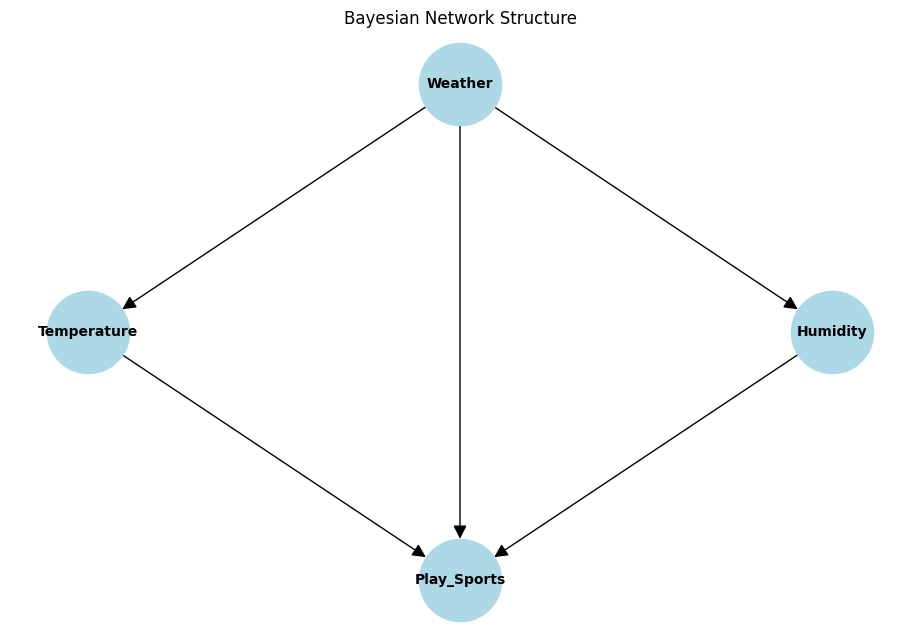

In [17]:
import networkx as nx

# Create directed graph
G = nx.DiGraph()

G.add_edges_from([
    ('Weather', 'Temperature'),
    ('Weather', 'Humidity'),
    ('Weather', 'Play_Sports'),
    ('Temperature', 'Play_Sports'),
    ('Humidity', 'Play_Sports')
])

# Draw graph
plt.figure(figsize=(9, 6))

pos = {
    'Weather': (0, 2),
    'Temperature': (-1, 1),
    'Humidity': (1, 1),
    'Play_Sports': (0, 0)
}

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3500,
    node_color='lightblue',
    font_size=10,
    font_weight='bold',
    arrows=True,
    arrowsize=20
)

plt.title("Bayesian Network Structure")

plt.show()

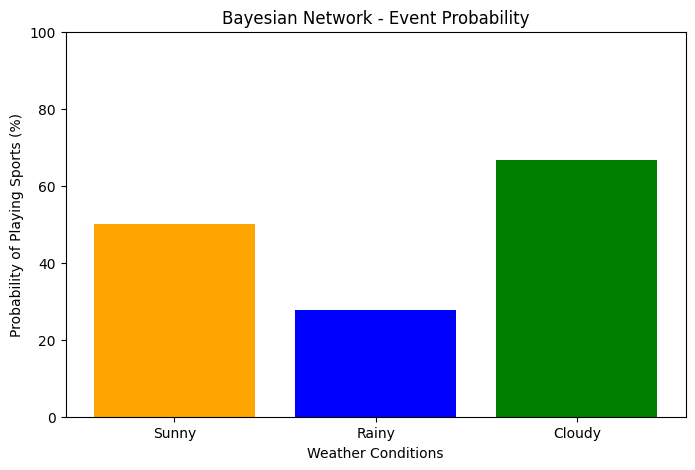

In [18]:
# Query probabilities for different weather conditions

weather_conditions = ['Sunny', 'Rainy', 'Cloudy']

probabilities = []

for weather in weather_conditions:

    result = inference.query(
        variables=['Play_Sports'],
        evidence={'Weather': weather}
    )

    yes_index = result.state_names['Play_Sports'].index('Yes')

    probabilities.append(result.values[yes_index] * 100)

# Plot graph

plt.figure(figsize=(8, 5))

plt.bar(
    weather_conditions,
    probabilities,
    color=['orange', 'blue', 'green']
)

plt.xlabel("Weather Conditions")
plt.ylabel("Probability of Playing Sports (%)")

plt.title("Bayesian Network - Event Probability")

plt.ylim(0, 100)

plt.show()

In [19]:
# New evidence
evidence = {
    'Weather': 'Cloudy',
    'Temperature': 'Mild',
    'Humidity': 'Normal'
}

# Perform inference
result = inference.query(
    variables=['Play_Sports'],
    evidence=evidence
)

# Display probability
print("New Evidence:", evidence)

print("\nProbability Distribution:")
print(result)

yes_index = result.state_names['Play_Sports'].index('Yes')

prob = result.values[yes_index]

print("\nLikelihood of Playing Sports:", round(prob * 100, 2), "%")

New Evidence: {'Weather': 'Cloudy', 'Temperature': 'Mild', 'Humidity': 'Normal'}

Probability Distribution:
+------------------+--------------------+
| Play_Sports      |   phi(Play_Sports) |
+==================+====================+
| Play_Sports(No)  |             0.0000 |
+------------------+--------------------+
| Play_Sports(Yes) |             1.0000 |
+------------------+--------------------+

Likelihood of Playing Sports: 100.0 %
